# Myocardial infarction: reference reproduction and consistent $\hat\rho$ sensitivity

**Primary acceptance criterion:** reproduce the wide black-stem figure immediately above
“Evaluate the probability of the presence of a change point using rho_hat” in the original notebook.
The original notebook and checkpoint are never overwritten. This notebook deliberately starts from
that **frozen fitted-experiment checkpoint**, not from a new fit or a new covariance estimate.
It recomputes the reference likelihood weights from the stored fixed-point solutions, tests them
against the stored curve, and reruns the fixed-point procedure for eigenvalue sensitivity.
This is reproducibility conditional on the archived fit, **not a fresh raw-data refit**.
Select the repository's `.venv-phase1/bin/python` interpreter (JAX/JAXlib 0.6.2).
The other working environment in this repository uses a different JAX version and does **not**
reproduce the archived Monte Carlo fixed points; the notebook rejects that mismatch explicitly.

## Fixed experimental specification

The archived analysis used UCI myocardial-infarction data, binary target `ZSN` (the fourth target
from the end), removed eight missing-age rows, sorted by age, removed AGE from predictors,
mean-imputed and centered the other 110 predictors, whitened with covariance ridge $10^{-6}$,
and scaled the design by $n^{-1/2}$: $n=1692$, $p=110$, $\delta=1692/110$.
It used two coefficient vectors, no intercept, unpenalized logistic WERM with fixed $L=2$,
$\Delta_n=1$, and fitting weights $\phi_{1i}=1-i/n$, $\phi_{2i}=i/n$ for $i=1,\ldots,n$.
The archived $\hat\rho$ was obtained using a **squared-loss auxiliary estimation procedure**
(three diagonal and three joint iterations, logistic observation model); it is not re-estimated
with logistic loss here. Seed 42, archived uniform simulation noise, and archived debiased
logistic scores are fixed throughout. Different fitting weights or re-estimated scores would
change the experiment rather than test sensitivity of this reference result.

## Scale and support (intentional legacy conventions)

For the 63 archived candidates, the displayed quantity is
$w_j=p_j\exp(\ell_j-\max_k\ell_k)$ with $p_j=1/63$.
These are **relative likelihood weights**, not normalized probabilities. The gold-standard
figure retains this exact scale and styling as an **original-prior reference only**.
The probability tables and normalized sensitivity plots instead use the count-uniform prior
specified below; the reference figure must not be interpreted as the posterior under that new prior.
The package's logistic likelihood uses a Gaussian/probit approximation, so “posterior” below
means that package's plug-in approximate posterior, not an exact Bayesian logistic posterior.

The legacy grid includes $\eta=0$ (all observations use coefficient vector 2) and $\eta=n$
(all use vector 1). Both represent **0 chgpts**. The latter has age NaN and is omitted
visually by the original plotting function but **retained in every normalization**. We retain both
to reproduce the reference. The **original** prior probability of **0 chgpts** was $2/63$.
For the updated analysis, place a uniform prior over the number of change points:
$P(K=0)=P(K=1)=1/2$. Conditional on $K=1$, use a uniform prior over the 61 valid
age-grid split locations, giving each mass $1/(2\cdot61)$.
Conditional on $K=0$, give equal weight to the two archived constant-signal configurations,
so each boundary has mass $1/4$. This is an explicit mixture over the two fitted coefficient
vectors, not a newly fitted one-coefficient null model. This preserves the archived likelihoods.
The event **1 chgpt** is $0<\eta<n$; no new `-1` candidate is appended, which would duplicate an
existing constant-signal configuration. The finite-age point at age 26 is also a boundary/null state.
Fitting weights $\phi$ and the posterior configuration prior serve different roles. The fitted
estimator is unchanged; only the posterior prior is updated, identically in all nine scenarios.

In [1]:
import os
# Set before numerical imports; each of the 36 workers uses one BLAS thread.
for name in ('OPENBLAS_NUM_THREADS', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ[name] = '1'
os.environ['JAX_ENABLE_X64'] = 'true'
os.environ['JAX_PLATFORMS'] = 'cpu'
from pathlib import Path
import hashlib, pickle, json, platform, warnings, time, importlib.metadata
from itertools import product
import numpy as np
import pandas as pd
import jax
jax.config.update('jax_enable_x64', True)  # BEFORE unpickling JAX arrays: do not truncate rho!
jax.config.update('jax_threefry_partitionable', True)
assert jax.__version__ == '0.6.2', 'Select .venv-phase1/bin/python (JAX 0.6.2) to reproduce this experiment.'
assert importlib.metadata.version('jaxlib') == '0.6.2'
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from joblib import Parallel, delayed, parallel_config
import WERM.posterior as posterior_module
import WERM.general_fixed_point_eqns as fp
import WERM.model
from IPython.display import display

REFERENCE = Path('results/myocardial_infarction_posterior_exact_one_chgpt.pkl')
reference_sha256 = hashlib.sha256(REFERENCE.read_bytes()).hexdigest()
assert reference_sha256 == '2531ba1839f2f747cee6299162429b44c8fed5b3c2c4c0ac640adc23709cd456', 'The gold-standard checkpoint changed; do not silently replace the reference.'
with REFERENCE.open('rb') as handle:
    reference = pickle.load(handle)
N_JOBS = 36
FP_SETTINGS = dict(num_samples_mult=100, maxiter=500, lr=0.01, tol=1e-4, history_size=5)
eta = np.asarray(reference['η_arr_subsampled'], dtype=int)
ages = np.asarray(reference['unique_ages'], dtype=float)
prior = np.asarray(reference['p_η_arr_subsampled'], dtype=float)
rho_base = np.asarray(reference['ρ_hat'], dtype=float)
theta = reference['Theta_deb']
y = reference['y_prep']
phi = reference['ϕ']
epsilon = reference['ε']
delta = reference['δ']
n, p = reference['X_prep'].shape
# Use the original loss expression, rather than quietly changing its numerical implementation.
M = lambda u, v: jnp.log(1 + jnp.exp(u)) - jnp.multiply(v, u)
subkeys = jax.random.split(reference['MASTER_KEY'], len(eta))
levels = {'-10%': 0.9, '0%': 1.0, '+10%': 1.1}
level_order = list(levels)
eigvals, eigvecs = np.linalg.eigh(rho_base)
assert (n, p) == (1692, 110)
assert eta.shape == (63, 1) and len(np.unique(eta)) == 63
assert np.all(np.diff(eta[:, 0]) > 0)
assert eta[0, 0] == 0 and eta[-1, 0] == n
assert np.isnan(ages[-1]) and np.isfinite(ages[:-1]).all()
np.testing.assert_allclose(prior, np.full(63, 1/63), rtol=0, atol=1e-15)
np.testing.assert_allclose(phi, np.array([1-np.arange(1,n+1)/n, np.arange(1,n+1)/n]))
assert np.min(eigvals) > 0 and np.isfinite(theta).all()
print('Reference SHA256:', reference_sha256)
print('n, p:', n, p, '; rho eigenvalues:', eigvals)
print('Precision:', jax.config.jax_enable_x64, '; fixed-point settings:', FP_SETTINGS)
print('Archived squared-loss covariance estimate:\n', rho_base)

provenance = dict(reference_sha256=reference_sha256, fixed_point_settings=FP_SETTINGS,
                  python=platform.python_version(), numpy=np.__version__, jax=jax.__version__,
                  versions={name: importlib.metadata.version(name) for name in ('jaxlib','jaxopt','scipy')},
                  jax_threefry_partitionable=True,
                  source_sha256={name: hashlib.sha256(Path(name).read_bytes()).hexdigest()
                    for name in ('WERM/posterior.py','WERM/general_fixed_point_eqns.py','WERM/model.py')})
run_fingerprint = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()[:16]
OUTPUT = Path('results') / ('myocardial_rho_final_' + run_fingerprint)
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Versioned analysis directory:', OUTPUT)

/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Reference SHA256: 2531ba1839f2f747cee6299162429b44c8fed5b3c2c4c0ac640adc23709cd456
n, p: 1692 110 ; rho eigenvalues: [7.93291753e-09 6.04531218e-01]
Precision: True ; fixed-point settings: {'num_samples_mult': 100, 'maxiter': 500, 'lr': 0.01, 'tol': 0.0001, 'history_size': 5}
Archived squared-loss covariance estimate:
 [[ 0.01840574 -0.10386562]
 [-0.10386562  0.58612549]]
Versioned analysis directory: results/myocardial_rho_final_0319bd095d3a48b3


In [2]:
def summarize_weights(weights, eta, n):
    w = np.asarray(weights, dtype=float).reshape(-1)
    locations = np.asarray(eta).reshape(-1)
    if len(w) != len(locations) or not np.isfinite(w).all() or np.any(w < 0) or w.sum() <= 0:
        raise ValueError('Invalid posterior weights')
    if np.any((locations < 0) | (locations > n)):
        raise ValueError('Support must be the archived grid in [0,n]')
    q = w / w.sum()
    interior = (locations > 0) & (locations < n)
    presence = float(q[interior].sum())
    absence = float(q[~interior].sum())
    np.testing.assert_allclose(presence + absence, 1, atol=1e-12)
    return dict(weights=w, probabilities=q, presence=presence, absence=absence,
                boundary_zero=float(q[locations == 0].sum()),
                boundary_n=float(q[locations == n].sum()), interior=interior)

def evaluate(rho, nu, kappa):
    # Independent log-space evaluation verifies the package's two normalization modes.
    log_likelihood = np.asarray(posterior_module.logP_V_Y_given_η_jax_allη_logistic(
        eta, theta, y, rho, 1.0, nu, kappa), dtype=float).reshape(-1)
    assert np.isfinite(log_likelihood).all()
    expected_w = prior * np.exp(log_likelihood - log_likelihood.max())
    expected_q = np.exp(np.log(prior) + log_likelihood - logsumexp(np.log(prior) + log_likelihood))
    w = np.asarray(posterior_module.exact_posterior_logistic(
        eta, prior, theta, y, rho, 1.0, nu, kappa, normalize=False)).reshape(-1)
    q = np.asarray(posterior_module.exact_posterior_logistic(
        eta, prior, theta, y, rho, 1.0, nu, kappa, normalize=True)).reshape(-1)
    np.testing.assert_allclose(w, expected_w, rtol=1e-9, atol=1e-12)
    np.testing.assert_allclose(q, expected_q, rtol=1e-9, atol=1e-12)
    result = summarize_weights(w, eta, n)
    np.testing.assert_allclose(result['probabilities'], q, rtol=1e-9, atol=1e-12)
    result['log_likelihood'] = log_likelihood
    return result

baseline = evaluate(rho_base, reference['nu_arr'], reference['kappa_arr'])
saved_weights = np.asarray(reference['posterior'], dtype=float).reshape(-1)
np.testing.assert_allclose(baseline['weights'], saved_weights, rtol=1e-10, atol=1e-12)
assert ages[np.argmax(saved_weights)] == 81
baseline_error = float(np.max(np.abs(baseline['weights'] - saved_weights)))
print(f'REFERENCE REPRODUCTION PASSED: maximum absolute difference {baseline_error:.3g}')
print(f'Weight sum = {saved_weights.sum():.12f}; peak age = 81; peak weight = {saved_weights.max():.12f}')

REFERENCE REPRODUCTION PASSED: maximum absolute difference 0
Weight sum = 0.202325047012; peak age = 81; peak weight = 0.015873015873


## Gold-standard figure — unchanged data, scale, and plotting function
The curve below uses the archived weights after the reconstruction assertion above. The missing-age endpoint remains in the analysis, although the original plotting function masks it. This vertical scale is not normalized probability.

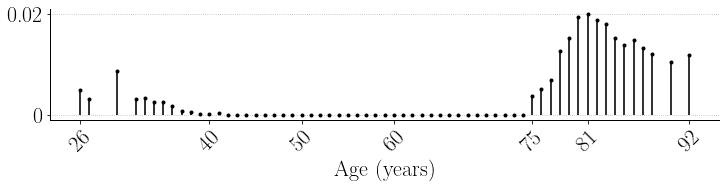

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

# --- 1. Compact Style Setup (JRSSB / Tufte Style) ---
plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'font.size': 10,
    'axes.linewidth': 1.0,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 72,         # High resolution
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'savefig.pad_inches': 0.1
})

x_y_labels_fontsize = 22

def plot_posterior_compact(unique_ages, posterior, output_path=None):
    """
    Generates a minimalist stem plot suitable for JRSSB.
    Includes robust NaN handling.
    """
    # --- Data Cleaning ---
    # 1. Flatten to ensuring 1D arrays
    ages = np.array(unique_ages).flatten()
    probs = np.array(posterior).flatten()
    
    # 2. Create a mask to keep only Finite values (removes NaN and Inf)
    # We check both arrays to ensure alignment is preserved
    mask = np.isfinite(ages) & np.isfinite(probs)
    
    # 3. Apply mask
    ages = ages[mask]
    probs = probs[mask]
    
    if len(ages) == 0:
        print("Warning: No valid data points found (all inputs were NaN/Inf).")
        return None, None

    # --- Plotting ---
    fig, ax = plt.subplots(figsize=(12, 2.0))
    
    # JRSSB Style: Black stems, no baseline
    markerline, stemlines, baseline = ax.stem(
        ages, probs,
        linefmt='k-', markerfmt='ko', basefmt=' ', 
    )
    
    # Fine-tune visual elements
    plt.setp(stemlines, linewidth=2.0, alpha=0.8)
    plt.setp(markerline, markersize=4, markeredgewidth=0)

    # --- Smart Ticks ---
    # Find peak (MAP estimate)
    max_idx = np.argmax(probs)
    max_age = ages[max_idx]
    max_prob = probs[max_idx]

    # Calculate integer boundaries safely
    min_age_scalar = int(np.floor(np.min(ages)))
    max_age_scalar = int(np.ceil(np.max(ages)))

    # Generate Decade ticks (e.g. 40, 50, 60...)
    # Ensure start is a multiple of 10
    start_decade = (min_age_scalar // 10 + 1) * 10
    if start_decade < max_age_scalar:
        decades = np.arange(start_decade, max_age_scalar, 10)
    else:
        decades = np.array([])

    # Define critical points (Min, Max, Peak, and 75 as requested)
    critical_points = np.array([min_age_scalar, max_age_scalar, max_age, 75])
    
    # Combine, unique, and sort ticks
    # Filter out ticks that might be outside the valid range due to float/int rounding
    all_ticks = np.unique(np.concatenate((decades, critical_points)))
    all_ticks = all_ticks[(all_ticks >= min_age_scalar) & (all_ticks <= max_age_scalar)]
    
    # ax.set_xticks(all_ticks)
    ax.set_xticks([26, 40, 50, 60, 75, 81, 92]) # Add minor ticks for the original specified ages
    
    # Y-axis: Minimalist (Zero and Peak only)
    ax.set_yticks([0, max_prob])
    ax.set_yticklabels(['0', f'{max_prob:.2f}']) 
    
    ax.tick_params(axis='x', rotation=45, labelsize=x_y_labels_fontsize)
    ax.tick_params(axis='y', labelsize=x_y_labels_fontsize)

    # --- Labels ---
    ax.set_xlabel(r'Age (years)', fontsize=x_y_labels_fontsize)
    # ax.set_ylabel(r'Posterior', fontsize=x_y_labels_fontsize)
    ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)

    if output_path:
        fig.savefig(output_path, bbox_inches='tight', transparent=True)
    
    return fig, ax



fig, ax = plot_posterior_compact(ages, saved_weights)
plt.show()

## Probability of 0 chgpts versus 1 chgpt using the same $\hat\rho$ and grid

Reweight the **same 63 saved likelihoods** using $P(K=0)=P(K=1)=1/2$, then normalize.
The two boundary states
are grouped as **0 chgpts**; every other candidate represents **1 chgpt**. This differs from the original notebook's later `-1`-augmented
grid and altered fitting/debiasing weights, which defined a different experiment.
The original table's numerical entries are therefore not targets for this consistent analysis.

In [4]:
def apply_count_prior(result, eta, n):
    locations = np.asarray(eta).reshape(-1)
    one_change = (locations > 0) & (locations < n)
    zero_changes = (locations == 0) | (locations == n)
    assert one_change.any() and zero_changes.sum() == 2
    assert np.all(one_change | zero_changes)
    count_prior = np.where(one_change, 0.5 / one_change.sum(), 0.25)
    np.testing.assert_allclose(count_prior[one_change].sum(), 0.5, atol=1e-15)
    np.testing.assert_allclose(count_prior[zero_changes].sum(), 0.5, atol=1e-15)
    ll = np.asarray(result['log_likelihood'], dtype=float)
    weights = count_prior * np.exp(ll - ll.max())
    updated = summarize_weights(weights, eta, n)
    return dict(result, reference_weights=result.get('reference_weights', result['weights']),
                count_prior=count_prior, **updated)

baseline = apply_count_prior(baseline, eta, n)
baseline_probabilities = pd.DataFrame([{
    'P(1 chgpt)': baseline['presence'],
    'P(0 chgpts)': baseline['absence'],
    'P(eta=0)': baseline['boundary_zero'],
    'P(eta=n)': baseline['boundary_n'],
    'prior P(0 chgpts)': float(baseline['count_prior'][(eta[:,0] == 0) | (eta[:,0] == n)].sum()),
}])
display(baseline_probabilities.style.format('{:.6f}'))
print(f"P(1 chgpt) = {baseline['presence']:.8f}; P(0 chgpts) = {baseline['absence']:.8f}")

,P(1 chgpt),P(0 chgpts),P(eta=0),P(eta=n),prior P(0 chgpts)
0,0.334942,0.665058,0.207389,0.457669,0.500000


P(1 chgpt) = 0.33494240; P(0 chgpts) = 0.66505760


## Paired full-factorial eigenvalue sensitivity

Independently multiply the ascending eigenvalues of $\hat\rho$ by 0.9, 1, or 1.1 (nine cases),
holding eigenvectors, data, fitted coefficients, debiased scores, fitting weights, grid, and prior
fixed. The **same candidate-specific random keys** and archived simulation noise are used in
every scenario. Recompute fixed points with 100 Monte Carlo replicates, 500 averaged Anderson
iterations, learning rate 0.01, history size 5, and diagnostic tolerance $10^{-4}$, as in the source.
The solver runs all 500 iterations; its returned “success” field is actually a residual norm.
These residuals are reported, not interpreted as successful convergence.

Before perturbing $\rho$, rerun **all 63 baseline fixed points** and check their coefficients,
covariances, and resulting weights against the archived reference. Stop on disagreement rather
than mix an unreproduced baseline with fresh perturbations. No baseline renormalization is used
to force agreement. The smallest eigenvalue is very close to zero; sensitivity here is conditional
on the archived estimate and numerical procedure, not a guarantee of statistical calibration.

Every scenario has an atomic checkpoint with a reference/code/environment fingerprint. Restarting
this cell reuses only matching completed scenarios. Set `FORCE_RECOMPUTE=True` to recompute them.

In [5]:
FORCE_RECOMPUTE = False

def pin_worker(cpu_ids):
    # Limit each XLA thread pool before the worker imports/initializes JAX.
    import os, multiprocessing
    worker_number = int(multiprocessing.current_process().name.rsplit('-', 1)[-1])
    os.sched_setaffinity(0, {cpu_ids[(worker_number-1) % len(cpu_ids)]})

worker_cpus = sorted(os.sched_getaffinity(0))[:N_JOBS]
assert len(worker_cpus) == N_JOBS, 'This run requests 36 available CPUs.'

def compute_candidate(i, rho):
    sol = fp.compute_single_fixed_point(
        eta[i], M, rho, delta, phi, epsilon, n, WERM.model.q_logistic_model, subkeys[i],
        **FP_SETTINGS)
    return tuple(np.asarray(value) for value in sol)

def solve_scenario(scenario):
    scales = np.array([levels[level] for level in scenario])
    rho = rho_base.copy() if scenario == ('0%', '0%') else eigvecs @ np.diag(eigvals * scales) @ eigvecs.T
    np.testing.assert_allclose(np.linalg.eigvalsh(rho), eigvals * scales, rtol=1e-7, atol=1e-15)
    assert np.linalg.eigvalsh(rho).min() > 0
    key = '_'.join(str(int(100*levels[level])) for level in scenario)
    path = OUTPUT / ('scenario_' + key + '.pkl')
    if path.exists() and not FORCE_RECOMPUTE:
        with path.open('rb') as handle:
            record = pickle.load(handle)
        assert record['provenance'] == provenance and tuple(record['scenario']) == scenario
        np.testing.assert_array_equal(record['rho'], rho)
        print('Loaded checked scenario', scenario, flush=True)
        return record
    print('Computing scenario', scenario, 'with', N_JOBS, 'jobs', flush=True)
    started = time.monotonic()
    with parallel_config(backend='loky', inner_max_num_threads=1):
        solutions = Parallel(n_jobs=N_JOBS, initializer=pin_worker, initargs=(worker_cpus,))(
            delayed(compute_candidate)(i, rho) for i in range(len(eta)))
    nu = np.asarray([sol[1] for sol in solutions])
    kappa = np.asarray([sol[2] for sol in solutions])
    residuals = np.asarray([sol[3] for sol in solutions], dtype=float).reshape(-1)
    assert np.isfinite(nu).all() and np.isfinite(kappa).all() and np.isfinite(residuals).all()
    record = dict(scenario=scenario, rho=rho, nu=nu, kappa=kappa, residuals=residuals,
                  provenance=provenance, elapsed_seconds=time.monotonic()-started,
                  **evaluate(rho, nu, kappa))
    temporary = path.with_suffix('.tmp')
    with temporary.open('wb') as handle:
        pickle.dump(record, handle)
    temporary.replace(path)
    print('Saved', scenario, '; max residual =', residuals.max(), flush=True)
    return record

fresh_baseline = solve_scenario(('0%', '0%'))
np.testing.assert_allclose(fresh_baseline['nu'], reference['nu_arr'], rtol=1e-7, atol=1e-9)
np.testing.assert_allclose(fresh_baseline['kappa'], reference['kappa_arr'], rtol=1e-7, atol=1e-9)
np.testing.assert_allclose(fresh_baseline['weights'], saved_weights, rtol=1e-6, atol=1e-10)
print('FRESH BASELINE FIXED-POINT REPRODUCTION PASSED', flush=True)
# Keep the literal archived curve at the central panel, after verifying the fresh procedure.
scenarios = {('0%', '0%'): dict(fresh_baseline, **baseline)}
for scenario in product(level_order, repeat=2):
    if scenario != ('0%', '0%'):
        scenarios[scenario] = solve_scenario(scenario)
assert len(scenarios) == 9
scenarios = {key: apply_count_prior(result, eta, n) for key, result in scenarios.items()}
print('All nine scenarios completed and checked.')

Loaded checked scenario ('0%', '0%')


FRESH BASELINE FIXED-POINT REPRODUCTION PASSED


Loaded checked scenario ('-10%', '-10%')


Loaded checked scenario ('-10%', '0%')


Loaded checked scenario ('-10%', '+10%')


Loaded checked scenario ('0%', '-10%')


Loaded checked scenario ('0%', '+10%')


Loaded checked scenario ('+10%', '-10%')


Loaded checked scenario ('+10%', '0%')


Loaded checked scenario ('+10%', '+10%')


All nine scenarios completed and checked.


## Consistent probability table and numerical diagnostics
Every entry uses the same support and normalization. Both endpoint probabilities are included explicitly so the hidden-age mass cannot disappear from the reported probability.

In [6]:
rows = []
for scenario in product(level_order, repeat=2):
    result = scenarios[scenario]
    rows.append({
        'lambda_1': scenario[0], 'lambda_2': scenario[1],
        'P(1 chgpt)': result['presence'], 'P(0 chgpts)': result['absence'],
        'P(eta=0)': result['boundary_zero'], 'P(eta=n)': result['boundary_n'],
        'weight sum': result['weights'].sum(),
        'max FP residual': result['residuals'].max(),
        'FP residuals below tolerance': int((result['residuals'] < FP_SETTINGS['tol']).sum()),
        'total variation vs baseline': 0.5*np.abs(result['probabilities'] - baseline['probabilities']).sum(),
    })
summary = pd.DataFrame(rows)
absence_table = summary.pivot(index='lambda_1', columns='lambda_2', values='P(0 chgpts)').reindex(index=level_order, columns=level_order)
np.testing.assert_allclose(absence_table.loc['0%', '0%'], baseline_probabilities['P(0 chgpts)'].iloc[0], atol=1e-12)
np.testing.assert_allclose(summary['P(1 chgpt)'] + summary['P(0 chgpts)'], 1, atol=1e-12)
print('P(0 chgpts):')
display(absence_table.style.format('{:.6f}'))
print('Full diagnostics:')
display(summary.style.format({col: '{:.6f}' for col in summary.select_dtypes('float').columns}))
print(absence_table.to_latex(float_format=lambda value: f'{value:.6f}', escape=True))
if (summary['max FP residual'] >= FP_SETTINGS['tol']).any():
    print('CAUTION: fixed-point residuals exceed tolerance. These results reproduce the finite-iteration reference procedure; they are not certified converged posteriors.')
summary.to_csv(OUTPUT / 'sensitivity_summary_uniform_count_prior.csv', index=False)

P(0 chgpts):


lambda_2,-10%,0%,+10%
lambda_1,,,
-10%,0.677902,0.664964,0.646544
0%,0.677889,0.665058,0.646591
+10%,0.677899,0.665035,0.646591


Full diagnostics:


,lambda_1,lambda_2,P(1 chgpt),P(0 chgpts),P(eta=0),P(eta=n),weight sum,max FP residual,FP residuals below tolerance,total variation vs baseline
0,-10%,-10%,0.322098,0.677902,0.244092,0.433811,0.327237,0.059957,0,0.048352
1,-10%,0%,0.335036,0.664964,0.207160,0.457804,0.292779,0.063850,0,0.000234
2,-10%,+10%,0.353456,0.646544,0.164064,0.482481,0.265183,0.066312,0,0.051456
3,0%,-10%,0.322111,0.677889,0.244052,0.433837,0.327217,0.059959,0,0.048315
4,0%,0%,0.334942,0.665058,0.207389,0.457669,0.292866,0.063850,0,0.000000
5,0%,+10%,0.353409,0.646591,0.164169,0.482422,0.265216,0.066312,0,0.051358
6,+10%,-10%,0.322101,0.677899,0.244056,0.433843,0.327213,0.059959,0,0.048305
7,+10%,0%,0.334965,0.665035,0.207322,0.457713,0.292838,0.063850,0,0.000078
8,+10%,+10%,0.353409,0.646591,0.164170,0.482422,0.265216,0.066312,0,0.051364


\begin{tabular}{lrrr}
\toprule
lambda_2 & -10\% & 0\% & +10\% \\
lambda_1 &  &  &  \\
\midrule
-10\% & 0.677902 & 0.664964 & 0.646544 \\
0\% & 0.677889 & 0.665058 & 0.646591 \\
+10\% & 0.677899 & 0.665035 & 0.646591 \\
\bottomrule
\end{tabular}

CAUTION: fixed-point residuals exceed tolerance. These results reproduce the finite-iteration reference procedure; they are not certified converged posteriors.


## Original-prior reference sensitivity — original figure scale
The center panel reproduces the gold-standard curve. These reference panels retain the original uniform-over-configurations prior and are not the updated count-uniform posterior. Only finite-age candidates can be drawn. The corrected probability table and normalized plots below use the count-uniform prior.

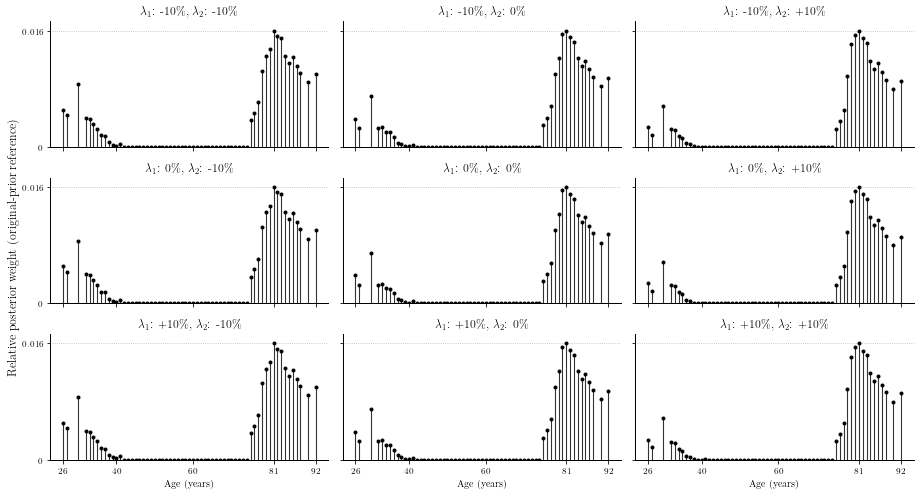

In [7]:
def plot_sensitivity(field, ylabel):
    fig, axes = plt.subplots(3, 3, figsize=(13, 7), sharex=True, sharey=True)
    finite = np.isfinite(ages)
    ymax = max(result[field][finite].max() for result in scenarios.values())
    for row, level_1 in enumerate(level_order):
        for col, level_2 in enumerate(level_order):
            ax = axes[row, col]
            values = scenarios[(level_1, level_2)][field]
            ax.vlines(ages[finite], 0, values[finite], color='black', linewidth=1.1, alpha=0.8)
            ax.plot(ages[finite], values[finite], 'ko', markersize=3)
            ax.set_title(r'$\lambda_1$: '+level_1.replace('%', r'\%')+r', $\lambda_2$: '+level_2.replace('%', r'\%'))
            ax.set_ylim(0, 1.08*ymax)
            ax.set_xticks([26, 40, 60, 81, 92])
            ax.set_yticks([0, ymax])
            ax.set_yticklabels(['0', f'{ymax:.3f}'])
            ax.grid(axis='y', linestyle=':', color='gray', alpha=0.6)
            if row == 2: ax.set_xlabel('Age (years)')
    fig.supylabel(ylabel)
    fig.tight_layout()
    plt.show()

plot_sensitivity('reference_weights', 'Relative posterior weight (original-prior reference)')

## Count-uniform prior: normalized posterior sensitivity
These curves use prior probabilities of 1/2 for 0 chgpts and 1/2 for 1 chgpt, with uniform conditional location probabilities. Normalization includes all 63 configurations, not merely the visible ages. The curves are not conditioned on 1 chgpt.

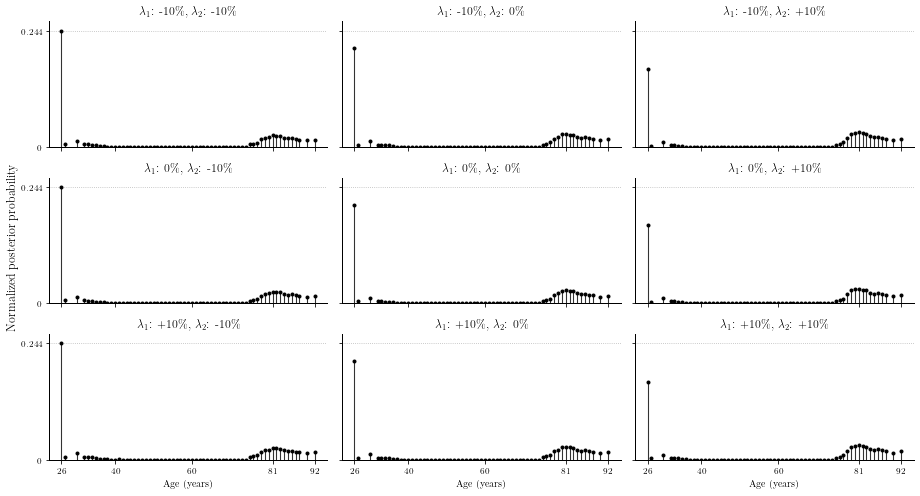

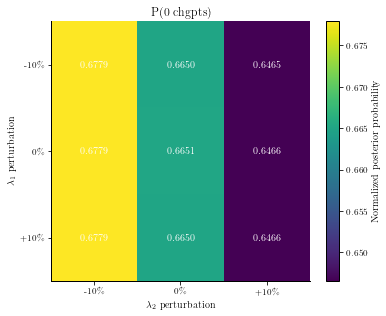

Completed: exact reference figure, consistent presence probabilities, sensitivity tables and plots.


In [8]:
plot_sensitivity('probabilities', 'Normalized posterior probability')
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(absence_table.to_numpy(), cmap='viridis', aspect='auto')
ax.set_xticks(range(3), [level.replace('%', r'\%') for level in level_order])
ax.set_yticks(range(3), [level.replace('%', r'\%') for level in level_order])
ax.set_xlabel(r'$\lambda_2$ perturbation')
ax.set_ylabel(r'$\lambda_1$ perturbation')
ax.set_title('P(0 chgpts)')
for row in range(3):
    for col in range(3):
        ax.text(col, row, f'{absence_table.iloc[row,col]:.4f}', ha='center', va='center', color='white')
fig.colorbar(image, ax=ax, label='Normalized posterior probability')
fig.tight_layout()
plt.show()
print('Completed: exact reference figure, consistent presence probabilities, sensitivity tables and plots.')